# Лестница жизни фьючерсных контрактов

Ноутбук показывает, какие конкретные `futures contract (фьючерсные контракты)` присутствуют в `dfs_5min.pickle`, и строит две визуализации:

1. для каждого рынка — первые 6 контрактов, отсортированных по контрактному месяцу и году;
2. для всех годных рынков — общий доступный временной диапазон, то есть от первой до последней зарегистрированной даты.

Исходный файл не изменяется. Результаты сохраняются в папку `contract_life_ladder_output` рядом с ноутбуком.

In [1]:
from pathlib import Path
import json
import pickle
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams['figure.dpi'] = 130
plt.rcParams['savefig.dpi'] = 160

In [2]:
ROOT = Path('.')
DATA_PATH = ROOT / 'dfs_5min.pickle'
CANDIDATES_PATH = ROOT / 'coverage_audit_dfs_5min' / '04_candidate_markets.csv'
OUT_DIR = ROOT / 'contract_life_ladder_output'
FIG_DIR = OUT_DIR / 'figures'

OUT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(f'Файл не найден рядом с ноутбуком: {DATA_PATH.resolve()}')
if not CANDIDATES_PATH.exists():
    raise FileNotFoundError(f'Не найден файл кандидатов: {CANDIDATES_PATH.resolve()}')

pd.DataFrame([{
    'data_path': str(DATA_PATH.resolve()),
    'candidates_path': str(CANDIDATES_PATH.resolve()),
    'output_dir': str(OUT_DIR.resolve()),
}])

,data_path,candidates_path,output_dir
0,C:\Users\jack\Jupyter_files\QUANT_TRAIDING\Fit...,C:\Users\jack\Jupyter_files\QUANT_TRAIDING\Fit...,C:\Users\jack\Jupyter_files\QUANT_TRAIDING\Fit...


## Загрузка данных

Файл большой, поэтому загрузка может занять время и несколько гигабайт оперативной памяти.

In [3]:
candidates = pd.read_csv(CANDIDATES_PATH)
MARKETS = candidates.loc[
    candidates['usable_for_first_pass'].astype(str).str.lower() == 'true',
    'name'
].tolist()

with DATA_PATH.open('rb') as f:
    dfs = pickle.load(f)

len(MARKETS), MARKETS

(28,
 ['ZC',
  'ZS',
  'ZL',
  'ZM',
  'ZW',
  'KE',
  'RS',
  'CL',
  'HO',
  'RB',
  'NG',
  'QA',
  'LF',
  'LE',
  'GF',
  'HE',
  'SB',
  'SW',
  'CC',
  'CA',
  'E6',
  'D6',
  'B6',
  'DX',
  'A6',
  'J6',
  'S6',
  'N6'])

## Парсинг контрактного месяца из `Symbol`

Используется стандартная фьючерсная кодировка месяцев: `F (январь)`, `G (февраль)`, `H (март)`, `J (апрель)`, `K (май)`, `M (июнь)`, `N (июль)`, `Q (август)`, `U (сентябрь)`, `V (октябрь)`, `X (ноябрь)`, `Z (декабрь)`.

In [4]:
MONTH_CODES = {
    'F': 1, 'G': 2, 'H': 3, 'J': 4, 'K': 5, 'M': 6,
    'N': 7, 'Q': 8, 'U': 9, 'V': 10, 'X': 11, 'Z': 12,
}
MONTH_NAMES_RU = {
    1: 'янв', 2: 'фев', 3: 'мар', 4: 'апр', 5: 'май', 6: 'июн',
    7: 'июл', 8: 'авг', 9: 'сен', 10: 'окт', 11: 'ноя', 12: 'дек',
}


def parse_futures_symbol(symbol):
    text = str(symbol)
    match = re.search(r'([FGHJKMNQUVXZ])(\d{1,4})$', text)
    if not match:
        return pd.Series({
            'month_code': None,
            'contract_month': np.nan,
            'year_code': None,
            'contract_year': np.nan,
            'contract_order': np.nan,
            'parse_ok': False,
        })
    month_code, year_code = match.groups()
    year_int = int(year_code)
    if len(year_code) == 1:
        contract_year = 2010 + year_int
    elif len(year_code) == 2:
        contract_year = 2000 + year_int
    else:
        contract_year = year_int
    contract_month = MONTH_CODES[month_code]
    return pd.Series({
        'month_code': month_code,
        'contract_month': contract_month,
        'year_code': year_code,
        'contract_year': contract_year,
        'contract_order': contract_year * 12 + contract_month,
        'parse_ok': True,
    })

## Таблица жизни контрактов

Каждая строка — один `Symbol (символ контракта)` внутри рынка. `first_seen` и `last_seen` показывают промежуток, где контракт реально присутствует в файле. Это не юридическая `expiration (экспирация)`, а наблюдаемая жизнь в данных.

In [5]:
life_rows = []

for market in MARKETS:
    frame = dfs[market]
    work = frame[['Date', 'Symbol', 'Volume']].copy()
    work['Date'] = pd.to_datetime(work['Date'], errors='coerce')
    work['Volume'] = pd.to_numeric(work['Volume'], errors='coerce')
    grouped = work.dropna(subset=['Date', 'Symbol']).groupby('Symbol', dropna=False)
    for symbol, part in grouped:
        parsed = parse_futures_symbol(symbol)
        life_rows.append({
            'market': market,
            'symbol': symbol,
            'first_seen': part['Date'].min(),
            'last_seen': part['Date'].max(),
            'rows': int(len(part)),
            'volume_sum': float(part['Volume'].sum(skipna=True)),
            **parsed.to_dict(),
        })

contract_life = pd.DataFrame(life_rows)
contract_life['life_days'] = (contract_life['last_seen'] - contract_life['first_seen']).dt.total_seconds() / 86400
contract_life['contract_label'] = contract_life.apply(
    lambda row: f"{row['symbol']} ({MONTH_NAMES_RU.get(int(row['contract_month']), '?')} {int(row['contract_year'])})" if row['parse_ok'] else str(row['symbol']),
    axis=1,
)
contract_life = contract_life.sort_values(['market', 'contract_order', 'first_seen', 'symbol']).reset_index(drop=True)
contract_life.head(20)

,market,symbol,first_seen,last_seen,rows,volume_sum,month_code,contract_month,year_code,contract_year,contract_order,parse_ok,life_days,contract_label
0,A6,A6U08,2008-07-01 07:25:00,2008-09-11 15:45:00,3503,9094.0,U,9,08,2008,24105,True,72.347222,A6U08 (сен 2008)
1,A6,A6Z08,2008-09-12 01:30:00,2008-12-11 23:55:00,9332,708808.0,Z,12,08,2008,24108,True,90.934028,A6Z08 (дек 2008)
2,A6,A6H09,2008-12-12 00:00:00,2009-03-11 23:50:00,16134,1700424.0,H,3,09,2009,24111,True,89.993056,A6H09 (мар 2009)
3,A6,A6M09,2009-03-12 00:10:00,2009-06-10 23:55:00,17334,3047724.0,M,6,09,2009,24114,True,90.989583,A6M09 (июн 2009)
4,A6,A6U09,2009-06-11 00:00:00,2009-09-09 23:50:00,17600,4543029.0,U,9,09,2009,24117,True,90.993056,A6U09 (сен 2009)
5,A6,A6Z09,2009-09-10 00:00:00,2009-12-09 23:55:00,17529,5446320.0,Z,12,09,2009,24120,True,90.996528,A6Z09 (дек 2009)
6,A6,A6H10,2009-12-10 00:00:00,2010-03-10 23:55:00,17190,5241146.0,H,3,10,2010,24123,True,90.996528,A6H10 (мар 2010)
7,A6,A6M10,2010-03-11 00:00:00,2010-06-10 23:55:00,18018,6866629.0,M,6,10,2010,24126,True,91.996528,A6M10 (июн 2010)
8,A6,A6U10,2010-06-11 00:00:00,2010-09-08 23:55:00,17375,5781903.0,U,9,10,2010,24129,True,89.996528,A6U10 (сен 2010)
9,A6,A6Z10,2010-09-09 00:00:00,2010-12-09 23:55:00,18096,5872489.0,Z,12,10,2010,24132,True,91.996528,A6Z10 (дек 2010)


In [6]:
contract_life.to_csv(OUT_DIR / '01_contract_life_all.csv', index=False, encoding='utf-8-sig')

first6_contracts = (
    contract_life[contract_life['parse_ok']]
    .sort_values(['market', 'contract_order', 'first_seen', 'symbol'])
    .groupby('market', as_index=False)
    .head(6)
    .copy()
)
first6_contracts.to_csv(OUT_DIR / '02_first6_contract_life.csv', index=False, encoding='utf-8-sig')
first6_contracts.head(40)

,market,symbol,first_seen,last_seen,rows,volume_sum,month_code,contract_month,year_code,contract_year,contract_order,parse_ok,life_days,contract_label
0,A6,A6U08,2008-07-01 07:25:00,2008-09-11 15:45:00,3503,9094.0,U,9,08,2008,24105,True,72.347222,A6U08 (сен 2008)
1,A6,A6Z08,2008-09-12 01:30:00,2008-12-11 23:55:00,9332,708808.0,Z,12,08,2008,24108,True,90.934028,A6Z08 (дек 2008)
2,A6,A6H09,2008-12-12 00:00:00,2009-03-11 23:50:00,16134,1700424.0,H,3,09,2009,24111,True,89.993056,A6H09 (мар 2009)
3,A6,A6M09,2009-03-12 00:10:00,2009-06-10 23:55:00,17334,3047724.0,M,6,09,2009,24114,True,90.989583,A6M09 (июн 2009)
4,A6,A6U09,2009-06-11 00:00:00,2009-09-09 23:50:00,17600,4543029.0,U,9,09,2009,24117,True,90.993056,A6U09 (сен 2009)
5,A6,A6Z09,2009-09-10 00:00:00,2009-12-09 23:55:00,17529,5446320.0,Z,12,09,2009,24120,True,90.996528,A6Z09 (дек 2009)
61,B6,B6U08,2008-07-14 03:05:00,2008-09-10 15:05:00,4681,20850.0,U,9,08,2008,24105,True,58.500000,B6U08 (сен 2008)
62,B6,B6Z08,2008-09-11 02:35:00,2008-12-11 23:55:00,11090,1702520.0,Z,12,08,2008,24108,True,91.888889,B6Z08 (дек 2008)
63,B6,B6H09,2008-12-12 00:00:00,2009-03-11 23:55:00,16367,3950361.0,H,3,09,2009,24111,True,89.996528,B6H09 (мар 2009)
64,B6,B6M09,2009-03-12 00:05:00,2009-06-10 23:55:00,17349,4945914.0,M,6,09,2009,24114,True,90.993056,B6M09 (июн 2009)


## График первых 6 контрактов для одного рынка

Поменяй `MARKET_TO_SHOW`, чтобы посмотреть другой рынок. Например: `CL`, `RB`, `NG`, `ZC`, `ZS`, `E6`.

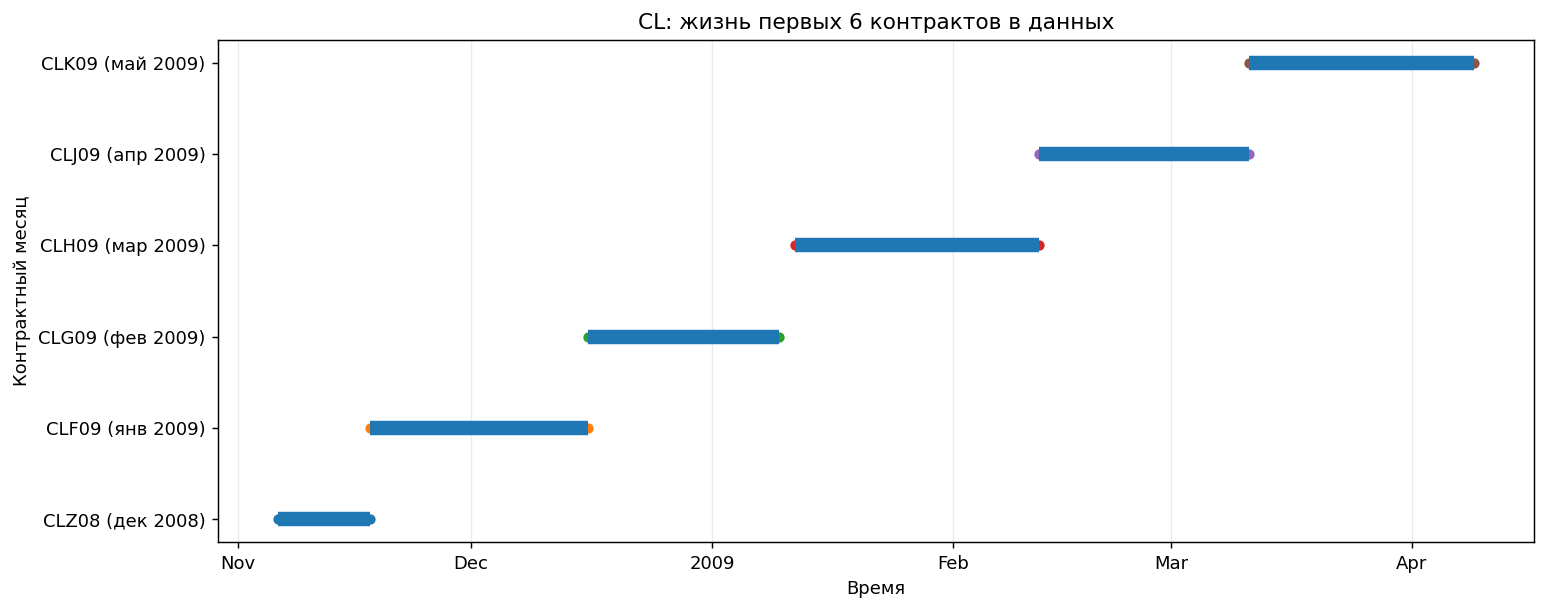

In [7]:
def plot_contract_ladder(market, max_contracts=6, save=True):
    data = (
        contract_life[(contract_life['market'] == market) & (contract_life['parse_ok'])]
        .sort_values(['contract_order', 'first_seen', 'symbol'])
        .head(max_contracts)
        .copy()
    )
    if data.empty:
        raise ValueError(f'Нет распарсенных контрактов для {market}')

    data = data.sort_values('contract_order').reset_index(drop=True)
    y = np.arange(len(data))

    fig, ax = plt.subplots(figsize=(12, 4.8))
    for i, row in data.iterrows():
        ax.hlines(y=i, xmin=row['first_seen'], xmax=row['last_seen'], linewidth=8)
        ax.scatter([row['first_seen'], row['last_seen']], [i, i], s=22)

    ax.set_yticks(y)
    ax.set_yticklabels(data['contract_label'])
    ax.set_xlabel('Время')
    ax.set_ylabel('Контрактный месяц')
    ax.set_title(f'{market}: жизнь первых {len(data)} контрактов в данных')
    ax.grid(axis='x', alpha=0.25)
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
    fig.tight_layout()

    if save:
        fig.savefig(FIG_DIR / f'{market}_first6_contract_life.png', bbox_inches='tight')
    return fig, ax


MARKET_TO_SHOW = 'CL'
plot_contract_ladder(MARKET_TO_SHOW);

## Сохранить такие графики для всех 29 рынков

In [8]:
for market in MARKETS:
    fig, ax = plot_contract_ladder(market, max_contracts=6, save=True)
    plt.close(fig)

saved_ladder_figures = sorted(path.name for path in FIG_DIR.glob('*_first6_contract_life.png'))
pd.DataFrame({'figure': saved_ladder_figures})

,figure
0,A6_first6_contract_life.png
1,B6_first6_contract_life.png
2,CA_first6_contract_life.png
3,CC_first6_contract_life.png
4,CL_first6_contract_life.png
5,D6_first6_contract_life.png
6,DX_first6_contract_life.png
7,E6_first6_contract_life.png
8,GF_first6_contract_life.png
9,HE_first6_contract_life.png


## Общий доступный срок по всем рынкам

Здесь каждый отрезок — полный наблюдаемый диапазон рынка: от самой ранней `Date (даты)` до самой поздней `Date (даты)` среди всех его контрактов.

In [9]:
market_life = (
    contract_life
    .groupby('market', as_index=False)
    .agg(
        first_seen=('first_seen', 'min'),
        last_seen=('last_seen', 'max'),
        contracts=('symbol', 'nunique'),
        rows=('rows', 'sum'),
    )
)
market_life['life_days'] = (market_life['last_seen'] - market_life['first_seen']).dt.total_seconds() / 86400
market_life = market_life.sort_values(['first_seen', 'market']).reset_index(drop=True)
market_life.to_csv(OUT_DIR / '03_market_life_ranges.csv', index=False, encoding='utf-8-sig')
market_life

,market,first_seen,last_seen,contracts,rows,life_days
0,ZC,2008-05-04 18:00:00,2023-08-10 11:00:00,66,744746,5575.708333
1,ZS,2008-05-04 18:00:00,2023-08-10 11:00:00,77,764096,5575.708333
2,ZW,2008-05-04 18:00:00,2023-08-10 11:00:00,77,724802,5575.708333
3,D6,2008-05-04 20:20:00,2023-08-10 11:00:00,62,1043303,5575.611111
4,DX,2008-05-04 20:20:00,2023-08-10 11:00:00,62,935991,5575.611111
5,KE,2008-05-04 20:20:00,2023-08-10 11:00:00,78,508681,5575.611111
6,NG,2008-05-04 20:20:00,2023-08-10 11:00:00,177,959491,5575.611111
7,RB,2008-05-04 20:20:00,2023-08-10 11:00:00,184,840805,5575.611111
8,S6,2008-05-04 20:20:00,2023-08-10 11:00:00,62,1020486,5575.611111
9,ZL,2008-05-04 20:20:00,2023-08-10 11:00:00,77,735005,5575.611111


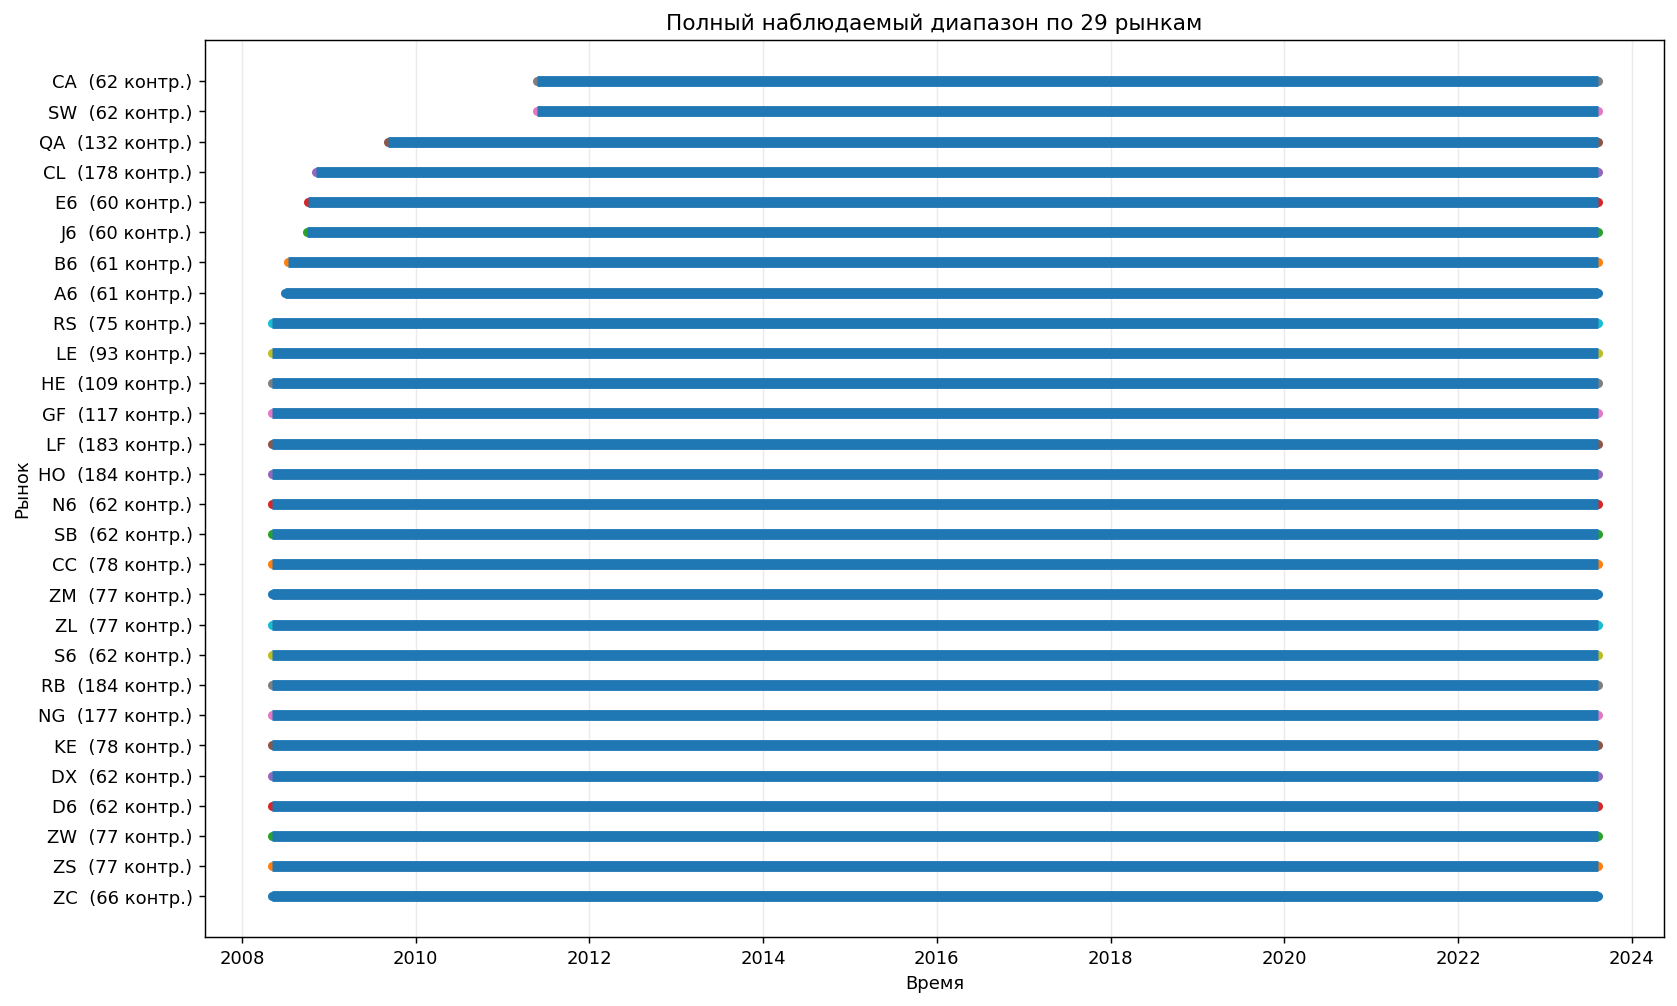

In [10]:
def plot_market_life_ranges(data, save=True):
    data = data.sort_values(['first_seen', 'market']).reset_index(drop=True)
    y = np.arange(len(data))

    fig, ax = plt.subplots(figsize=(13, max(7, len(data) * 0.28)))
    for i, row in data.iterrows():
        ax.hlines(y=i, xmin=row['first_seen'], xmax=row['last_seen'], linewidth=6)
        ax.scatter([row['first_seen'], row['last_seen']], [i, i], s=16)

    labels = data.apply(lambda row: f"{row['market']}  ({int(row['contracts'])} контр.)", axis=1)
    ax.set_yticks(y)
    ax.set_yticklabels(labels)
    ax.set_xlabel('Время')
    ax.set_ylabel('Рынок')
    ax.set_title('Полный наблюдаемый диапазон по 29 рынкам')
    ax.grid(axis='x', alpha=0.25)
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
    fig.tight_layout()

    if save:
        fig.savefig(FIG_DIR / 'all_markets_life_ranges.png', bbox_inches='tight')
    return fig, ax


plot_market_life_ranges(market_life);

## Сохранение манифеста

In [11]:
manifest = {
    'source_file': str(DATA_PATH.resolve()),
    'candidate_markets_source': str(CANDIDATES_PATH.resolve()),
    'output_dir': str(OUT_DIR.resolve()),
    'markets': MARKETS,
    'market_count': len(MARKETS),
    'contract_life_rows': int(len(contract_life)),
    'saved_csv': sorted(path.name for path in OUT_DIR.glob('*.csv')),
    'saved_figures': sorted(path.name for path in FIG_DIR.glob('*.png')),
    'note': 'first_seen/last_seen are observed data ranges, not legal expiration dates.',
}

with (OUT_DIR / '00_manifest.json').open('w', encoding='utf-8') as f:
    json.dump(manifest, f, ensure_ascii=False, indent=2, default=str)

readme = '''# Contract life ladder output

Generated by `contract_life_ladder.ipynb`.

Files:

- `01_contract_life_all.csv`: observed life of every parsed contract.
- `02_first6_contract_life.csv`: first six contracts per candidate market.
- `03_market_life_ranges.csv`: full observed date range per market.
- `figures/*_first6_contract_life.png`: ladder chart for each market.
- `figures/all_markets_life_ranges.png`: all-market coverage chart.

`first_seen` and `last_seen` are data availability dates, not official expiration dates.
'''
(OUT_DIR / 'README.md').write_text(readme, encoding='utf-8')

manifest

{'source_file': 'C:\\Users\\jack\\Jupyter_files\\QUANT_TRAIDING\\Fiter_2options\\dfs_5min.pickle',
 'candidate_markets_source': 'C:\\Users\\jack\\Jupyter_files\\QUANT_TRAIDING\\Fiter_2options\\coverage_audit_dfs_5min\\04_candidate_markets.csv',
 'output_dir': 'C:\\Users\\jack\\Jupyter_files\\QUANT_TRAIDING\\Fiter_2options\\contract_life_ladder_output',
 'markets': ['ZC',
  'ZS',
  'ZL',
  'ZM',
  'ZW',
  'KE',
  'RS',
  'CL',
  'HO',
  'RB',
  'NG',
  'QA',
  'LF',
  'LE',
  'GF',
  'HE',
  'SB',
  'SW',
  'CC',
  'CA',
  'E6',
  'D6',
  'B6',
  'DX',
  'A6',
  'J6',
  'S6',
  'N6'],
 'market_count': 28,
 'contract_life_rows': 2638,
 'saved_csv': ['01_contract_life_all.csv',
  '02_first6_contract_life.csv',
  '03_market_life_ranges.csv'],
 'saved_figures': ['A6_first6_contract_life.png',
  'B6_first6_contract_life.png',
  'CA_first6_contract_life.png',
  'CC_first6_contract_life.png',
  'CL_first6_contract_life.png',
  'D6_first6_contract_life.png',
  'DX_first6_contract_life.png',
  '